# Aprendizaje Colaborativo en el Borde Inalámbrico

**Escuela de Ingeniería Eléctrica (EIE) · Universidad de Costa Rica (UCR)**
**Curso:** IE-0629 Sistemas de Comunicación · **Tema:** Optimización colaborativa sobre canales inalámbricos (Semana 1)

---

## Objetivos de aprendizaje

Al terminar este laboratorio usted podrá:

1. Implementar desde cero (solo `numpy`) cuatro paradigmas de optimización colaborativa: **PSSGD**, **D2D**, **FedAvg** y **SlowMo**.
2. Medir su desempeño con métricas de telecomunicaciones: *rondas de comunicación*, *tiempo real simulado* y *bits transmitidos en el enlace de subida*.
3. Explicar cómo un canal con desvanecimiento Rayleigh y nodos rezagados (*stragglers*) penaliza a los esquemas síncronos.
4. Observar el fenómeno de **deriva del cliente** (*client drift*) cuando los datos son no-IID y se aumentan los pasos locales $H$.

> **No se requiere experiencia previa en Machine Learning.** El "modelo" es una regresión logística (un clasificador lineal con pérdida convexa), de modo que toda la atención recae en la dinámica de **optimización + comunicación**, no en la complejidad del modelo.

## 1. Formulación del problema

Tenemos $N$ dispositivos en el borde de una red inalámbrica. El dispositivo $i$ posee un conjunto de datos local $\mathcal{D}_i$ que **no puede (o no desea) enviar** al servidor. Se busca un único modelo $\boldsymbol{\theta}\in\mathbb{R}^p$ que resuelva el problema desacoplado

$$
\min_{\boldsymbol{\theta}} \; F(\boldsymbol{\theta}) = \frac{1}{N}\sum_{i=1}^{N} f_i(\boldsymbol{\theta}),
\qquad
f_i(\boldsymbol{\theta}) = \frac{1}{|\mathcal{D}_i|}\sum_{(\mathbf{x},y)\in\mathcal{D}_i} \ell(\boldsymbol{\theta};\mathbf{x},y) + \frac{\lambda}{2}\|\boldsymbol{\theta}\|^2 ,
$$

con pérdida logística $\ell(\boldsymbol{\theta};\mathbf{x},y)=\log\!\big(1+e^{-y\,\mathbf{x}^\top\boldsymbol{\theta}}\big)$ y etiquetas $y\in\{-1,+1\}$.

**Heterogeneidad (no-IID).** Cada $f_i$ tiene su propio mínimo $\boldsymbol{\theta}_i^\star\neq\boldsymbol{\theta}^\star$. Si cada nodo optimizara solo su $f_i$, obtendría modelos distintos entre sí; la colaboración consiste en **acordar** el minimizador de $F$ intercambiando únicamente *modelos o gradientes* por el canal.

## 2. ¿Qué tiene que ver el canal inalámbrico?

Cada intercambio de $p$ parámetros (a 32 bits cada uno) debe cruzar un enlace con capacidad de Shannon

$$
R_i = B\log_2\!\big(1+\mathrm{SNR}_i\,|h_i|^2\big)\ \text{[bit/s]},\qquad |h_i|^2\sim\mathrm{Exp}(1)\ \text{(Rayleigh)},
$$

de modo que el tiempo de transmisión $T_i = 32\,p/R_i$ es **aleatorio y de cola pesada** (un desvanecimiento profundo $|h|^2\to 0$ implica $R\to 0$ y $T\to\infty$). Un esquema **síncrono** que espera a los $N$ nodos paga

$$
T_{\text{ronda}} = \max_{i}\,\big(T^{\text{bajada}}_i + T^{\text{cómputo}}_i + T^{\text{subida}}_i\big),
$$

y el máximo de variables aleatorias crece con $N$ y con la dispersión de los enlaces. Así, **el desvanecimiento, los retardos variables y las restricciones de sincronismo de un sistema distribuido son el mismo problema visto desde dos capas distintas**: la capa física fija *cuánto tarda* cada ronda, y el algoritmo decide *cuántas rondas* hacen falta.

## 3. Mapa del laboratorio

| Parte | Algoritmo | Idea clave |
|---|---|---|
| A | **PSSGD** | Servidor de parámetros; 1 gradiente estocástico por nodo y ronda; espera a todos |
| B | **D2D** | Sin servidor; consenso con la matriz $\mathbf{W}=\mathbf{I}-\frac{1}{d_{\max}+1}(\mathbf{D}-\mathbf{A})$ |
| C | **FedAvg** | Muestreo de clientes, $H$ pasos locales, promediado en el servidor |
| D | **SlowMo** | FedAvg + *momentum* en el bucle exterior sobre el pseudogradiente |

## 2. Configuración del entorno

Todos los parámetros del experimento están en la celda siguiente. **Se invita a modificarlos** (por ejemplo `SKEW`, `REZAGADOS`, `BW_HZ`) y volver a ejecutar el cuaderno. La semilla `SEED` fija toda la aleatoriedad para que los resultados sean reproducibles.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

# ---------- Reproducibilidad ----------
SEED = 2026

# ---------- Datos y modelo ----------
N        = 10      # número de dispositivos
D_FEAT   = 20      # dimensión de los datos x (se añade un término de sesgo -> p = D_FEAT + 1 parámetros)
N_LOCAL  = 200     # muestras por dispositivo
LAMBDA   = 1e-2    # regularización L2 (hace F fuertemente convexa)
SKEW     = 1.0     # nivel de heterogeneidad: 0 = IID, 1 = fuertemente no-IID
BATCH    = 16      # tamaño del minilote para el gradiente estocástico

# ---------- Canal inalámbrico ----------
BW_HZ          = 50e3        # ancho de banda por enlace [Hz]
SNR_DB_MEDIO   = 10.0        # SNR media de un enlace típico [dB]
SNR_DB_REZAGADO = 0.0        # SNR media de un enlace débil [dB]
T_PASO_MS      = 2.0         # tiempo medio de UN paso de gradiente local [ms]
REZAGADOS      = {3: 5.0, 7: 4.0}   # {índice de nodo: factor de lentitud de cómputo}; además usan SNR_DB_REZAGADO

# ---------- Presupuesto de simulación ----------
T_MAX_MS   = 20_000   # presupuesto de tiempo simulado por algoritmo [ms]
R_MAX      = 5000     # tope de seguridad de rondas
N_SEMILLAS = 5        # repeticiones Monte Carlo (se promedian las curvas)

print(f"N={N} nodos | p={D_FEAT+1} parámetros | payload = {32*(D_FEAT+1)} bits por mensaje")

N=10 nodos | p=21 parámetros | payload = 672 bits por mensaje


### 2.1 Datos sintéticos heterogéneos (partición no-IID)

Se genera un problema de **clasificación binaria**: las etiquetas provienen de un modelo lineal verdadero con ruido. Para inducir **heterogeneidad** se hacen dos cosas:

* **Sesgo de etiquetas** (*label skew*): el nodo $i$ tiene una fracción de positivos distinta, desde ~5 % (nodo 0) hasta ~95 % (nodo 9).
* **Desplazamiento de características** (*feature shift*): cada nodo observa los datos con una media ligeramente distinta.

Con `SKEW=0` el reparto sería IID (todos los nodos ven la misma distribución).

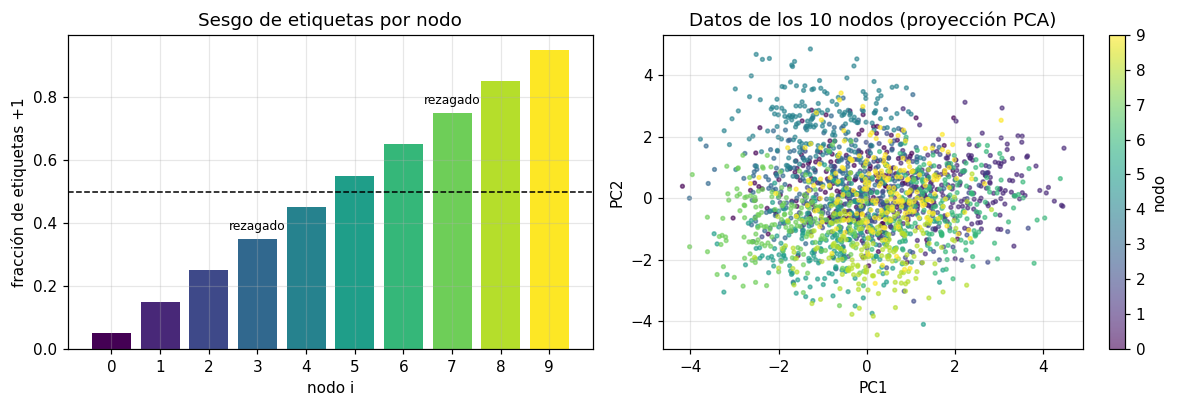

In [2]:
def generar_datos(N, n_local, d, skew, seed):
    # Devuelve Xc de forma (N, n_local, d+1) y yc de forma (N, n_local) con y en {-1,+1}.
    rng = np.random.default_rng(seed)
    w_true = rng.normal(size=d)
    w_true /= np.linalg.norm(w_true)                       # modelo verdadero (norma unitaria)
    frac_pos = 0.5 + skew * np.linspace(-0.45, 0.45, N)    # fracción de etiquetas +1 por nodo
    Xc, yc = [], []
    for i in range(N):
        mu = 0.5 * skew * rng.normal(size=d)               # desplazamiento de medias del nodo i
        X  = mu + rng.normal(size=(40 * n_local, d))       # "reserva" grande de muestras candidatas
        p1 = 1.0 / (1.0 + np.exp(-3.0 * X @ w_true))       # P(y=+1|x): modelo logístico verdadero
        y  = np.where(rng.random(len(p1)) < p1, 1.0, -1.0)
        n_pos = int(round(frac_pos[i] * n_local))
        idx = np.concatenate([np.flatnonzero(y > 0)[:n_pos],              # tomamos n_pos positivos
                              np.flatnonzero(y < 0)[:n_local - n_pos]])   # y el resto negativos
        rng.shuffle(idx)
        Xi = np.hstack([X[idx], np.ones((n_local, 1))])    # columna de unos = término de sesgo
        Xc.append(Xi); yc.append(y[idx])
    return np.array(Xc), np.array(yc), frac_pos

Xc, yc, frac_pos = generar_datos(N, N_LOCAL, D_FEAT, SKEW, SEED)
DIM = Xc.shape[2]                       # p = D_FEAT + 1
X_all, y_all = Xc.reshape(-1, DIM), yc.reshape(-1)   # unión de todos los datos (solo para EVALUAR)

# ---------- Visualización de la heterogeneidad ----------
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(range(N), (yc > 0).mean(axis=1), color=plt.cm.viridis(np.linspace(0, 1, N)))
ax[0].axhline(0.5, color="k", ls="--", lw=1)
ax[0].set(xlabel="nodo i", ylabel="fracción de etiquetas +1", title="Sesgo de etiquetas por nodo", xticks=range(N))
for i in REZAGADOS:
    ax[0].annotate("rezagado", (i, (yc[i] > 0).mean()), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)

# Proyección 2D (PCA vía SVD) de los datos, coloreada por nodo
Z = X_all[:, :D_FEAT] - X_all[:, :D_FEAT].mean(0)
_, _, Vt = np.linalg.svd(Z, full_matrices=False)
P = Z @ Vt[:2].T
nodo = np.repeat(np.arange(N), N_LOCAL)
sc = ax[1].scatter(P[:, 0], P[:, 1], c=nodo, cmap="viridis", s=6, alpha=0.6)
ax[1].set(xlabel="PC1", ylabel="PC2", title="Datos de los 10 nodos (proyección PCA)")
plt.colorbar(sc, ax=ax[1], label="nodo")
plt.tight_layout(); plt.show()

### 2.2 Pérdida, gradiente y solución óptima de referencia

Para $f_i$ logística con regularización:

$$
\nabla f_i(\boldsymbol{\theta}) = -\frac{1}{n}\sum_{k}\; y_k\,\mathbf{x}_k\,\sigma(-y_k\mathbf{x}_k^\top\boldsymbol{\theta}) + \lambda\boldsymbol{\theta},\qquad \sigma(z)=\frac{1}{1+e^{-z}} .
$$

Como $F$ es **convexa**, existe un único $\boldsymbol{\theta}^\star$. Lo calculamos con el método de Newton (centralizado, solo como *referencia* para medir la **subóptimalidad** $F(\boldsymbol{\theta})-F^\star$ de los algoritmos distribuidos).

In [3]:
def sigmoid(z):
    return 0.5 * (1.0 + np.tanh(0.5 * z))               # sigmoide numéricamente estable

def perdida(theta, X, y, lam=LAMBDA):
    z = X @ theta
    return np.mean(np.logaddexp(0.0, -y * z)) + 0.5 * lam * theta @ theta   # log(1+e^{-yz}) + (λ/2)||θ||²

def gradiente(theta, X, y, lam=LAMBDA):
    z = X @ theta
    return -(X.T @ (y * sigmoid(-y * z))) / len(y) + lam * theta           # ∇f(θ) del recuadro anterior

def perdida_global(theta):                               # F(θ): como n_i es igual, equivale a promediar los f_i
    return perdida(theta, X_all, y_all)

def precision_global(theta):                             # exactitud de clasificación sobre todos los datos
    return np.mean(np.sign(X_all @ theta) == y_all)

def optimo_newton(n_iter=30):
    th = np.zeros(DIM)
    for _ in range(n_iter):
        s = sigmoid(X_all @ th)
        Hess = (X_all.T * (s * (1 - s))) @ X_all / len(y_all) + LAMBDA * np.eye(DIM)   # Hessiana de F
        th = th - np.linalg.solve(Hess, gradiente(th, X_all, y_all))                   # paso de Newton
    return th

THETA_STAR = optimo_newton()
F_STAR = perdida_global(THETA_STAR)
print(f"F* = {F_STAR:.4f} | exactitud en el óptimo = {precision_global(THETA_STAR):.3f}")

# ¿Qué tan distintos son los óptimos locales? (esto es la heterogeneidad en términos de optimización)
dist = []
for i in range(N):
    th = np.zeros(DIM)
    for _ in range(30):
        s = sigmoid(Xc[i] @ th)
        Hess = (Xc[i].T * (s * (1 - s))) @ Xc[i] / N_LOCAL + LAMBDA * np.eye(DIM)
        th -= np.linalg.solve(Hess, gradiente(th, Xc[i], yc[i]))
    dist.append(np.linalg.norm(th - THETA_STAR))
print("‖θ_i* − θ*‖ por nodo:", np.round(dist, 2))

F* = 0.3570 | exactitud en el óptimo = 0.852
‖θ_i* − θ*‖ por nodo: [1.85 1.33 1.15 1.11 1.07 1.05 1.26 1.03 1.23 1.97]


### 2.3 Modelo del canal y de los nodos rezagados

Cada vez que un nodo transmite un modelo (o gradiente) de $p$ parámetros se sortea un coeficiente de desvanecimiento Rayleigh $|h|^2\sim\mathrm{Exp}(1)$ y se calcula

$$
T_{\text{enlace}} = \frac{32\,p}{B\log_2\!\big(1+\mathrm{SNR}\,|h|^2\big)}\ \text{[s]}.
$$

El tiempo de cómputo de $H$ pasos locales es $H\cdot T_{\text{paso}}\cdot s_i\cdot(\text{jitter log-normal})$, donde $s_i\ge1$ es el factor de lentitud del nodo. Los nodos en `REZAGADOS` combinan **cómputo lento** y **SNR baja**: son los *stragglers*.

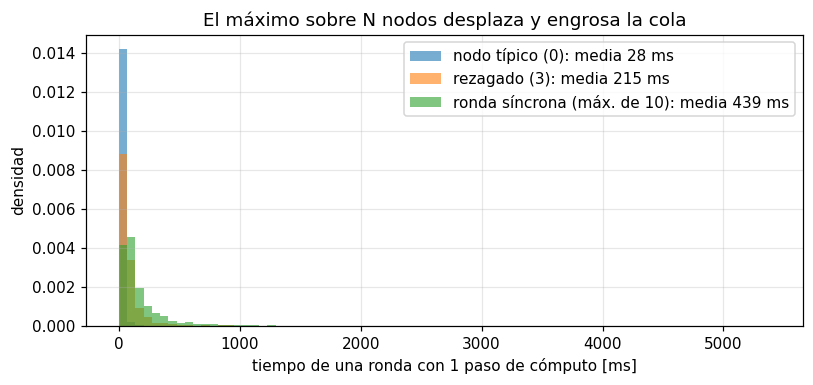

In [4]:
class CanalInalambrico:
    # Genera tiempos aleatorios de enlace (Shannon + Rayleigh) y de cómputo (con rezagados).
    def __init__(self, N, n_params, seed):
        self.rng = np.random.default_rng(seed)
        self.bits = 32 * n_params                          # carga útil: n_params números de 32 bits
        self.snr = np.full(N, 10 ** (SNR_DB_MEDIO / 10))   # SNR media lineal de cada enlace
        self.lento = np.ones(N)                            # factor de lentitud de cómputo
        for i, f in REZAGADOS.items():
            self.lento[i] = f
            self.snr[i] = 10 ** (SNR_DB_REZAGADO / 10)

    def t_enlace(self, idx):
        # Tiempo [ms] de transmitir el mensaje por los enlaces de los nodos 'idx' (una realización de desvanecimiento por nodo)
        idx = np.asarray(idx)
        g = self.rng.exponential(1.0, size=len(idx))       # |h|² ~ Exp(1)  <=> desvanecimiento Rayleigh
        C = BW_HZ * np.log2(1.0 + self.snr[idx] * g)       # capacidad de Shannon [bit/s]
        return 1e3 * self.bits / C                         # tiempo = bits / capacidad  [ms]

    def t_enlace_matriz(self):
        # Matriz N×N con el tiempo [ms] del enlace i->j (el emisor i fija la SNR media). Se usa en D2D.
        g = self.rng.exponential(1.0, size=(len(self.snr), len(self.snr)))
        C = BW_HZ * np.log2(1.0 + self.snr[:, None] * g)
        return 1e3 * self.bits / C

    def t_computo(self, idx, pasos):
        idx = np.asarray(idx)
        jitter = self.rng.lognormal(0.0, 0.2, size=len(idx))        # variabilidad de cómputo
        return pasos * T_PASO_MS * self.lento[idx] * jitter

def tiempo_ronda_servidor(canal, S, pasos):
    # Ronda con servidor: cada nodo en S recibe el modelo (bajada), calcula 'pasos' y sube su resultado.
    # El servidor es SÍNCRONO: debe esperar al más lento -> máximo sobre S.
    t_bajada = canal.t_enlace(S)
    t_calc   = canal.t_computo(S, pasos)
    t_subida = canal.t_enlace(S)
    return np.max(t_bajada + t_calc + t_subida)

# ---------- ¿Cuánto penaliza el "max" a un esquema síncrono? ----------
canal_demo = CanalInalambrico(N, DIM, SEED)
t_nodo_tipico = np.array([tiempo_ronda_servidor(canal_demo, [0], 1) for _ in range(4000)])
t_nodo_lento  = np.array([tiempo_ronda_servidor(canal_demo, [3], 1) for _ in range(4000)])
t_todos       = np.array([tiempo_ronda_servidor(canal_demo, np.arange(N), 1) for _ in range(4000)])

fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.linspace(0, np.percentile(t_todos, 99), 80)
ax.hist(t_nodo_tipico, bins, alpha=0.6, density=True, label=f"nodo típico (0): media {t_nodo_tipico.mean():.0f} ms")
ax.hist(t_nodo_lento,  bins, alpha=0.6, density=True, label=f"rezagado (3): media {t_nodo_lento.mean():.0f} ms")
ax.hist(t_todos,       bins, alpha=0.6, density=True, label=f"ronda síncrona (máx. de {N}): media {t_todos.mean():.0f} ms")
ax.set(xlabel="tiempo de una ronda con 1 paso de cómputo [ms]", ylabel="densidad", title="El máximo sobre N nodos desplaza y engrosa la cola")
ax.legend(); plt.tight_layout(); plt.show()

## 3. Implementación modular de los algoritmos

Primero, utilidades comunes: muestreo de minilotes (gradiente **estocástico**) y un registro del historial de cada experimento (ronda, tiempo simulado, bits subidos, pérdida y exactitud).

In [5]:
from collections import defaultdict

def minibatch(i, B, rng):
    # Muestrea B ejemplos del conjunto LOCAL del nodo i -> gradiente estocástico
    idx = rng.integers(0, N_LOCAL, size=B)
    return Xc[i][idx], yc[i][idx]

def registrar(h, ronda, tiempo, bits, theta, **extra):
    # Guarda las métricas globales evaluadas en el modelo 'theta'
    h["ronda"].append(ronda); h["tiempo"].append(tiempo); h["bits"].append(bits)
    h["perdida"].append(perdida_global(theta)); h["acc"].append(precision_global(theta))
    for k, v in extra.items():
        h[k].append(v)

def cerrar(h):
    return {k: np.array(v) for k, v in h.items()}

### Parte A — PSSGD (Parallel Synchronous SGD, servidor de parámetros)

En cada ronda $t$:

1. El servidor difunde $\boldsymbol{\theta}_t$.
2. Cada nodo calcula **un** gradiente estocástico local $\mathbf{g}_{i,t}=\nabla f_i(\boldsymbol{\theta}_t;\xi_{i,t})$ y lo sube.
3. El servidor **espera a todos** y actualiza
$$\boldsymbol{\theta}_{t+1}=\boldsymbol{\theta}_t-\eta\,\frac{1}{N}\sum_{i=1}^{N}\mathbf{g}_{i,t}.$$

Equivale a SGD con un minilote de tamaño $N\cdot B$, pero **cada paso cuesta una ronda de comunicación completa**, y esa ronda dura lo que tarde el nodo más lento.

In [6]:
def pssgd(eta, seed, t_max=T_MAX_MS, r_max=R_MAX, batch=BATCH):
    # PSSGD: 1 gradiente estocástico por nodo y por ronda; el servidor espera a TODOS.
    rng = np.random.default_rng(seed)
    canal = CanalInalambrico(N, DIM, seed + 1)
    theta = np.zeros(DIM)
    h = defaultdict(list); t = 0.0; bits = 0
    registrar(h, 0, t, bits, theta)
    for r in range(1, r_max + 1):
        G = np.stack([gradiente(theta, *minibatch(i, batch, rng)) for i in range(N)])   # g_{i,t}, i=1..N
        theta = theta - eta * G.mean(axis=0)                  # θ_{t+1} = θ_t − η · (1/N) Σ g_{i,t}
        t += tiempo_ronda_servidor(canal, np.arange(N), pasos=1)   # penalización del rezagado más lento
        bits += N * canal.bits                                # N mensajes de subida
        registrar(h, r, t, bits, theta)
        if t >= t_max: break
    return cerrar(h)

### Parte B — D2D (descentralizado, consenso con el Laplaciano del grafo)

No hay servidor. Los nodos forman un grafo no dirigido con matriz de adyacencia $\mathbf{A}$ y matriz de grados $\mathbf{D}$ (el Laplaciano es $\mathbf{L}=\mathbf{D}-\mathbf{A}$). Se usa la matriz de pesos

$$
\mathbf{W}=\mathbf{I}-\frac{1}{d_{\max}+1}\,(\mathbf{D}-\mathbf{A}),
$$

que es **simétrica y doblemente estocástica** si el grafo es conexo (sus filas y columnas suman 1). Cada nodo mantiene su propio modelo $\boldsymbol{\theta}_i$ y, en cada ronda, hace *adaptación + combinación*:

$$
\boldsymbol{\theta}_i^{t+1}=\sum_{j\in\mathcal{N}_i\cup\{i\}} W_{ij}\,\big(\boldsymbol{\theta}_j^{t}-\eta\,\mathbf{g}_{j,t}\big)
\quad\Longleftrightarrow\quad
\boldsymbol{\Theta}^{t+1}=\mathbf{W}\big(\boldsymbol{\Theta}^{t}-\eta\,\mathbf{G}^{t}\big).
$$

La velocidad con la que los modelos se ponen de acuerdo la fija el **segundo mayor valor propio** $|\lambda_2(\mathbf{W})|$: cuanto más cerca de 1, más lento es el consenso (grafos poco conectados, como el anillo).

anillo    | aristas=10 | d_max=2 | filas suman 1: True | |λ2(W)|=0.873
aleatorio | aristas=26 | d_max=8 | filas suman 1: True | |λ2(W)|=0.701


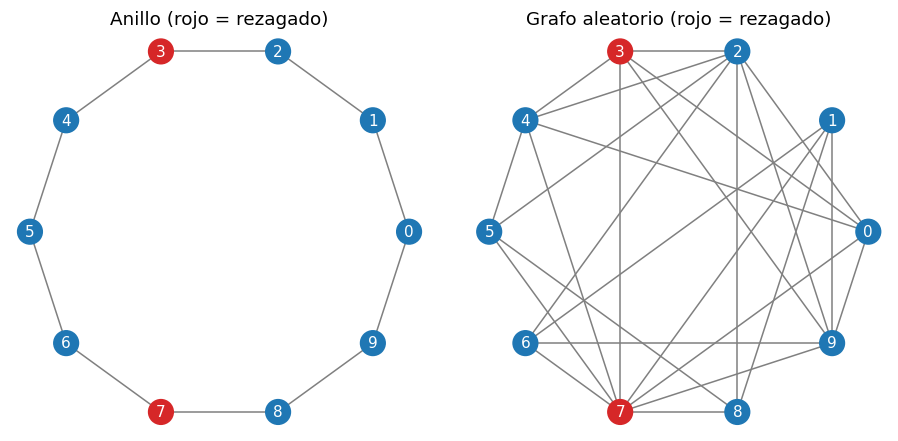

In [7]:
def construir_grafo(tipo="aleatorio", N=N, p=0.5, seed=SEED):
    # Devuelve la matriz de adyacencia A (simétrica, 0/1) de un anillo o de un grafo aleatorio conexo
    rng = np.random.default_rng(seed)
    if tipo == "anillo":
        A = np.zeros((N, N))
        for i in range(N):
            A[i, (i + 1) % N] = A[(i + 1) % N, i] = 1.0
        return A
    while True:                                              # Erdős–Rényi, se repite hasta que sea conexo
        U = np.triu((rng.random((N, N)) < p).astype(float), 1)
        A = U + U.T
        L = np.diag(A.sum(1)) - A
        if np.sort(np.linalg.eigvalsh(L))[1] > 1e-9:         # λ2(L) > 0  <=>  grafo conexo
            return A

def matriz_pesos(A):
    deg = A.sum(1)                                           # grados d_i
    D = np.diag(deg)
    dmax = deg.max()
    return np.eye(len(A)) - (D - A) / (dmax + 1.0)           # W = I − (D−A)/(d_max+1)

def info_grafo(A, nombre):
    W = matriz_pesos(A)
    lam = np.sort(np.abs(np.linalg.eigvalsh(W)))[::-1]       # |autovalores| de W, en orden decreciente
    print(f"{nombre:10s}| aristas={int(A.sum()//2):2d} | d_max={int(A.sum(1).max())} | "
          f"filas suman 1: {np.allclose(W.sum(1), 1)} | |λ2(W)|={lam[1]:.3f}")
    return W

GRAFO = "aleatorio"                                          # cambie a "anillo" y compare
A_ring, A_rand = construir_grafo("anillo"), construir_grafo("aleatorio")
W_ring, W_rand = info_grafo(A_ring, "anillo"), info_grafo(A_rand, "aleatorio")
A_D2D = {"anillo": A_ring, "aleatorio": A_rand}[GRAFO]

# ---------- Dibujo de las topologías (disposición circular) ----------
ang = 2 * np.pi * np.arange(N) / N
pos = np.c_[np.cos(ang), np.sin(ang)]
fig, ax = plt.subplots(1, 2, figsize=(8.5, 4))
for a, A, ttl in zip(ax, [A_ring, A_rand], ["Anillo", "Grafo aleatorio"]):
    for i in range(N):
        for j in range(i + 1, N):
            if A[i, j]: a.plot(*pos[[i, j]].T, color="gray", lw=1)
    colores = ["tab:red" if i in REZAGADOS else "tab:blue" for i in range(N)]
    a.scatter(pos[:, 0], pos[:, 1], s=260, c=colores, zorder=3)
    for i in range(N): a.text(*pos[i], str(i), ha="center", va="center", color="w", zorder=4)
    a.set(title=ttl + " (rojo = rezagado)", aspect="equal"); a.axis("off")
plt.tight_layout(); plt.show()

In [8]:
def d2d(eta, seed, A=A_D2D, t_max=T_MAX_MS, r_max=R_MAX, batch=BATCH):
    # D2D: cada nodo tiene su propio modelo; paso local + consenso Θ <- W(Θ − ηG). No hay servidor.
    rng = np.random.default_rng(seed)
    canal = CanalInalambrico(N, DIM, seed + 1)
    W = matriz_pesos(A)
    Theta = np.zeros((N, DIM))                                # fila i = modelo del nodo i
    h = defaultdict(list); t = 0.0; bits = 0
    registrar(h, 0, t, bits, Theta.mean(0), consenso=0.0)
    for r in range(1, r_max + 1):
        G = np.stack([gradiente(Theta[i], *minibatch(i, batch, rng)) for i in range(N)])
        Theta = W @ (Theta - eta * G)                         # adaptación (−ηG) + difusión/consenso (W·)
        th_bar = Theta.mean(0)                                # modelo promedio (W doblemente estocástica lo conserva)
        # --- tiempo: cada nodo calcula y luego envía a sus vecinos; la ronda termina cuando el enlace más lento termina
        t_calc = canal.t_computo(np.arange(N), 1)
        T_ij = canal.t_enlace_matriz()
        t_com = np.max(np.where(A > 0, T_ij, 0.0), axis=1)   # cada nodo espera a su enlace vecino más lento
        t += np.max(t_calc + t_com)                           # barrera síncrona entre todos los nodos
        bits += N * canal.bits                                # cada nodo difunde su modelo una vez por ronda
        registrar(h, r, t, bits, th_bar, consenso=np.mean(np.sum((Theta - th_bar) ** 2, axis=1)))  # error de consenso
        if t >= t_max: break
    return cerrar(h)

### Parte C — FedAvg (Federated Averaging)

En cada ronda $t$:

1. El servidor elige al azar un subconjunto $\mathcal{S}_t$ con una **fracción** $C$ de los clientes y les envía $\boldsymbol{\theta}_t$.
2. Cada cliente $i\in\mathcal{S}_t$ ejecuta **$H$ pasos de SGD local**: $\boldsymbol{\theta}_i^{(k+1)}=\boldsymbol{\theta}_i^{(k)}-\eta\,\nabla f_i(\boldsymbol{\theta}_i^{(k)};\xi)$, y sube la perturbación acumulada $\boldsymbol{\Delta}_{i,t}=\boldsymbol{\theta}_t-\boldsymbol{\theta}_i^{(H)}$.
3. El servidor promedia: $\boldsymbol{\theta}_{t+1}=\boldsymbol{\theta}_t-\frac{1}{|\mathcal{S}_t|}\sum_{i\in\mathcal{S}_t}\boldsymbol{\Delta}_{i,t}$.

Se comunica **una vez cada $H$ pasos**: se cambia cómputo (barato) por comunicación (cara). El costo es la **deriva del cliente**: con datos no-IID, cada modelo local se aleja hacia *su* mínimo $\boldsymbol{\theta}_i^\star$ durante los $H$ pasos. Medimos esa deriva como $\frac{1}{|\mathcal{S}_t|}\sum_i\|\boldsymbol{\theta}_i^{(H)}-\bar{\boldsymbol{\theta}}^{(H)}\|^2$.

In [9]:
def sgd_local(theta, i, H, eta, batch, rng):
    # H pasos de SGD local en el nodo i, partiendo del modelo global 'theta'
    th = theta.copy()
    for _ in range(H):
        th = th - eta * gradiente(th, *minibatch(i, batch, rng))     # θ ← θ − η ∇f_i(θ; ξ)
    return th

def fedavg(eta, H, seed, C=0.5, t_max=T_MAX_MS, r_max=R_MAX, batch=BATCH):
    # FedAvg: muestreo de una fracción C de clientes, H pasos locales, promedio en el servidor.
    rng = np.random.default_rng(seed)
    canal = CanalInalambrico(N, DIM, seed + 1)
    m = max(1, int(round(C * N)))                             # |S_t|
    theta = np.zeros(DIM)
    h = defaultdict(list); t = 0.0; bits = 0
    registrar(h, 0, t, bits, theta, deriva=0.0)
    for r in range(1, r_max + 1):
        S = rng.choice(N, size=m, replace=False)              # clientes seleccionados
        locales = np.stack([sgd_local(theta, i, H, eta, batch, rng) for i in S])   # θ_i^{(H)}
        Delta = theta - locales                               # Δ_{i,t} = θ_t − θ_i^{(H)}
        theta = theta - Delta.mean(axis=0)                    # θ_{t+1} = θ_t − (1/|S|) Σ Δ_{i,t}  (= promedio de modelos locales)
        deriva = np.mean(np.sum((locales - locales.mean(0)) ** 2, axis=1))   # dispersión de modelos locales
        t += tiempo_ronda_servidor(canal, S, pasos=H)         # espera al más lento de S (con H pasos de cómputo)
        bits += m * canal.bits
        registrar(h, r, t, bits, theta, deriva=deriva)
        if t >= t_max: break
    return cerrar(h)

### Parte D — SlowMo (FedAvg con *momentum* lento en el bucle exterior)

El bucle interno es **idéntico a FedAvg** ($H$ pasos locales). La diferencia está en el servidor, que interpreta el promedio de las perturbaciones como un **pseudogradiente** y le aplica *momentum*:

$$
\bar{\mathbf{G}}_t=\frac{1}{|\mathcal{S}_t|\,\eta}\sum_{i\in\mathcal{S}_t}\boldsymbol{\Delta}_{i,t},\qquad
\mathbf{m}_{t+1}=\beta\,\mathbf{m}_t+\bar{\mathbf{G}}_t,\qquad
\boldsymbol{\theta}_{t+1}=\boldsymbol{\theta}_t-\alpha\,\eta\,\mathbf{m}_{t+1}.
$$

Con $\beta=0$ y $\alpha=1$ se recupera exactamente FedAvg (porque $\alpha\eta\bar{\mathbf{G}}_t=\frac{1}{|\mathcal{S}_t|}\sum\boldsymbol{\Delta}_{i,t}$). El *momentum* promedia la dirección de varias rondas, lo que **amortigua el ruido y el sesgo** de cada ronda y acelera la convergencia **sin transmitir un solo bit adicional** (el momentum vive en el servidor).

In [10]:
def slowmo(eta, H, seed, alpha=1.0, beta=0.5, C=0.5, t_max=T_MAX_MS, r_max=R_MAX, batch=BATCH):
    # SlowMo: bucle interno = FedAvg; el servidor aplica momentum al pseudogradiente.
    rng = np.random.default_rng(seed)
    canal = CanalInalambrico(N, DIM, seed + 1)
    m = max(1, int(round(C * N)))
    theta, mom = np.zeros(DIM), np.zeros(DIM)                 # modelo global y momentum externo m_t
    h = defaultdict(list); t = 0.0; bits = 0
    registrar(h, 0, t, bits, theta, deriva=0.0)
    for r in range(1, r_max + 1):
        S = rng.choice(N, size=m, replace=False)
        locales = np.stack([sgd_local(theta, i, H, eta, batch, rng) for i in S])   # igual que FedAvg
        Delta = theta - locales                               # Δ_{i,t}
        G_bar = Delta.sum(axis=0) / (m * eta)                 # pseudogradiente  Ḡ_t = (1/(|S|η)) Σ Δ_{i,t}
        mom = beta * mom + G_bar                              # m_{t+1} = β m_t + Ḡ_t
        theta = theta - alpha * eta * mom                     # θ_{t+1} = θ_t − α η m_{t+1}
        deriva = np.mean(np.sum((locales - locales.mean(0)) ** 2, axis=1))
        t += tiempo_ronda_servidor(canal, S, pasos=H)         # mismo costo de red que FedAvg
        bits += m * canal.bits
        registrar(h, r, t, bits, theta, deriva=deriva)
        if t >= t_max: break
    return cerrar(h)

## 4. Simulación comparativa y métricas de telecomunicaciones

**Protocolo justo.** Los cuatro algoritmos usan el **mismo presupuesto de tiempo simulado** `T_MAX_MS` y los mismos modelos de canal y de datos. Cada uno corre `N_SEMILLAS` veces con semillas distintas y se grafica el promedio (banda = ±1 desviación estándar). La métrica es la **subóptimalidad** $F(\boldsymbol{\theta})-F^\star$ en escala logarítmica (para D2D se evalúa el modelo promedio $\bar{\boldsymbol{\theta}}$).

Hiperparámetros (tasa de aprendizaje $\eta$, $H$, $C$, $\alpha$, $\beta$) en la celda siguiente. Se eligieron con un pequeño barrido previo; **puede probar los suyos**.

In [11]:
# ---------- Hiperparámetros ----------
ETA_PS, ETA_D2D = 0.5, 0.5          # PSSGD y D2D (un paso por ronda)
ETA_FED         = 0.1               # FedAvg / SlowMo (paso local)
H_FED, C_FED    = 5, 0.5            # pasos locales y fracción de clientes por ronda
ALPHA, BETA     = 1.0, 0.5          # SlowMo: tasa global y momentum externo

def correr(fn, **kw):
    return [fn(seed=SEED + 100 * s, **kw) for s in range(N_SEMILLAS)]

resultados = {
    "PSSGD":  correr(pssgd,  eta=ETA_PS),
    "D2D":    correr(d2d,    eta=ETA_D2D),
    "FedAvg": correr(fedavg, eta=ETA_FED, H=H_FED, C=C_FED),
    "SlowMo": correr(slowmo, eta=ETA_FED, H=H_FED, C=C_FED, alpha=ALPHA, beta=BETA),
}
colores = {"PSSGD": "tab:blue", "D2D": "tab:green", "FedAvg": "tab:orange", "SlowMo": "tab:red"}

def curva_media(hists, xkey, ykey, x_max=None, transformar=lambda y: y, n=300):
    # Interpola cada corrida en una rejilla común y devuelve (rejilla, media, desviación)
    if x_max is None:
        x_max = min(h[xkey][-1] for h in hists)
    grid = np.linspace(0, x_max, n)
    Y = np.array([np.interp(grid, h[xkey], transformar(h[ykey])) for h in hists])
    return grid, Y.mean(0), Y.std(0)

subopt = lambda y: np.maximum(y - F_STAR, 1e-9)        # F(θ) − F*

# ---------- Resumen numérico ----------
print(f"{'Algoritmo':8s} | {'rondas':>7s} | {'F−F* final':>10s} | {'exactitud':>9s} | {'Mbit subidos':>12s}")
for nom, hs in resultados.items():
    print(f"{nom:8s} | {np.mean([h['ronda'][-1] for h in hs]):7.0f} | "
          f"{np.mean([subopt(h['perdida'])[-1] for h in hs]):10.2e} | "
          f"{np.mean([h['acc'][-1] for h in hs]):9.3f} | "
          f"{np.mean([h['bits'][-1] for h in hs]) / 1e6:12.2f}")

Algoritmo |  rondas | F−F* final | exactitud | Mbit subidos
PSSGD    |      68 |   4.41e-03 |     0.853 |         0.46
D2D      |      29 |   1.76e-02 |     0.853 |         0.20
FedAvg   |      73 |   4.80e-03 |     0.853 |         0.25
SlowMo   |      73 |   3.17e-03 |     0.853 |         0.25


### 4.1 Pérdida vs. rondas de comunicación, tiempo simulado y bits

* **Panel (a):** ¿cuántos *intercambios por el canal* necesita cada esquema?
* **Panel (b):** ¿cuánto *tiempo real* tarda, una vez incorporados el desvanecimiento y los rezagados?
* **Panel (c):** ¿cuántos *bits de subida* (proxy de energía de transmisión) consume?

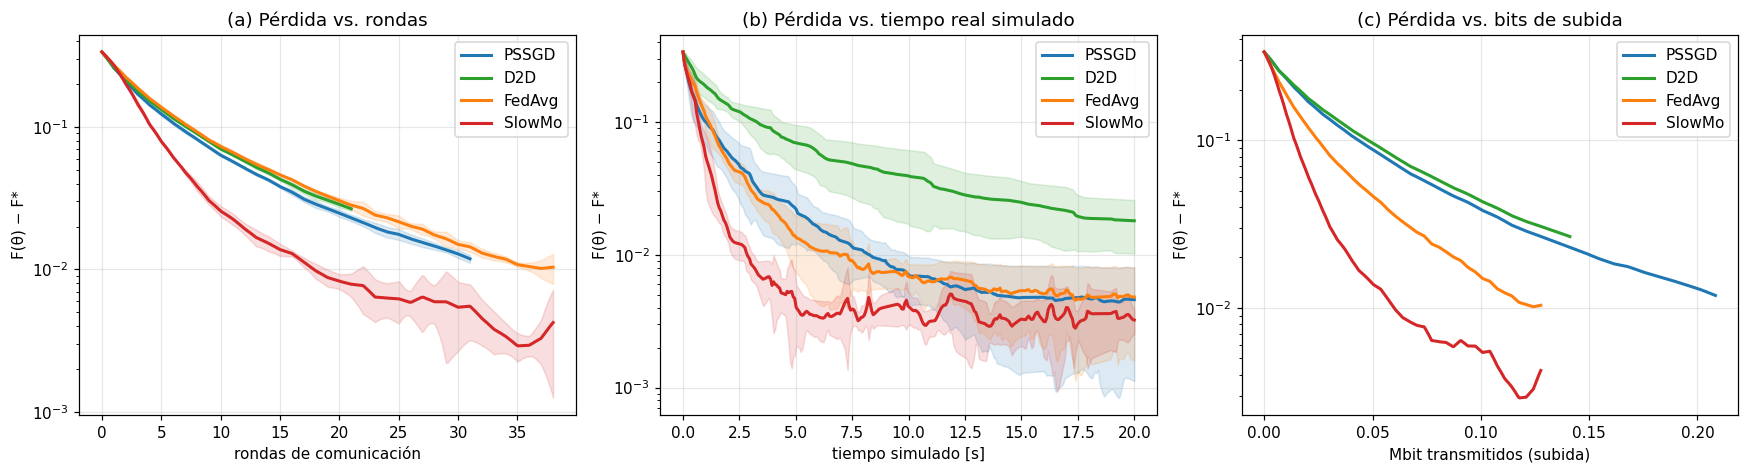

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for nom, hs in resultados.items():
    # (a) vs rondas
    g, m, s = curva_media(hs, "ronda", "perdida", transformar=subopt)
    ax[0].plot(g, m, color=colores[nom], label=nom, lw=2)
    ax[0].fill_between(g, np.maximum(m - s, 1e-9), m + s, color=colores[nom], alpha=0.15)
    # (b) vs tiempo [s]
    g, m, s = curva_media(hs, "tiempo", "perdida", x_max=T_MAX_MS, transformar=subopt)
    ax[1].plot(g / 1e3, m, color=colores[nom], label=nom, lw=2)
    ax[1].fill_between(g / 1e3, np.maximum(m - s, 1e-9), m + s, color=colores[nom], alpha=0.15)
    # (c) vs bits subidos
    g, m, s = curva_media(hs, "bits", "perdida", transformar=subopt)
    ax[2].plot(g / 1e6, m, color=colores[nom], label=nom, lw=2)
for a in ax: a.set_yscale("log"); a.set_ylabel("F(θ) − F*"); a.legend()
ax[0].set(xlabel="rondas de comunicación", title="(a) Pérdida vs. rondas")
ax[1].set(xlabel="tiempo simulado [s]", title="(b) Pérdida vs. tiempo real simulado")
ax[2].set(xlabel="Mbit transmitidos (subida)", title="(c) Pérdida vs. bits de subida")
plt.tight_layout(); plt.show()

**Cómo leer las gráficas.** Antes de continuar, escriba en una frase qué espera: ¿cuál algoritmo gana por *rondas*? ¿cuál por *tiempo*? ¿por qué podrían no coincidir? Luego contraste con lo observado.

* PSSGD es el más "limpio" por ronda (todos los nodos aportan), pero **una ronda = un paso**, y cada ronda cuesta lo que tarda el peor enlace.
* FedAvg/SlowMo hacen $H$ pasos por ronda y solo esperan al más lento **de los seleccionados**.
* D2D evita al servidor, pero su consenso es solo aproximado en cada ronda (depende de $\lambda_2(\mathbf{W})$).

**Lo que probablemente observará.** FedAvg y sobre todo SlowMo reducen el error mucho más rápido *por unidad de tiempo* al inicio (cada ronda hace $H$ pasos y espera solo a $|\mathcal{S}_t|$ nodos). PSSGD, más lento pero sin deriva, termina alcanzándolos hacia el final del presupuesto, mientras que FedAvg/SlowMo muestran una meseta causada por la heterogeneidad y el ruido de $H$ pasos locales. D2D paga tiempo de aire por la barrera entre todos los enlaces vecinos del grafo denso. Verifique estas afirmaciones en sus gráficas en lugar de darlas por ciertas.

### 4.2 Deriva del cliente (*client drift*): efecto de $H\in\{1,5,20\}$ en FedAvg

Con datos no-IID, aumentar $H$ **reduce rondas** (y por tanto comunicación) pero cada cliente se aleja hacia su propio óptimo local. Si $H$ es demasiado grande, el promedio de modelos "desalineados" **no converge a $\boldsymbol{\theta}^\star$** con paso constante: se estanca en una meseta de subóptimalidad.

Ejecutamos FedAvg con $H\in\{1,5,20\}$ y el mismo $\eta$ durante un número fijo de rondas, y además comparamos en tiempo simulado.

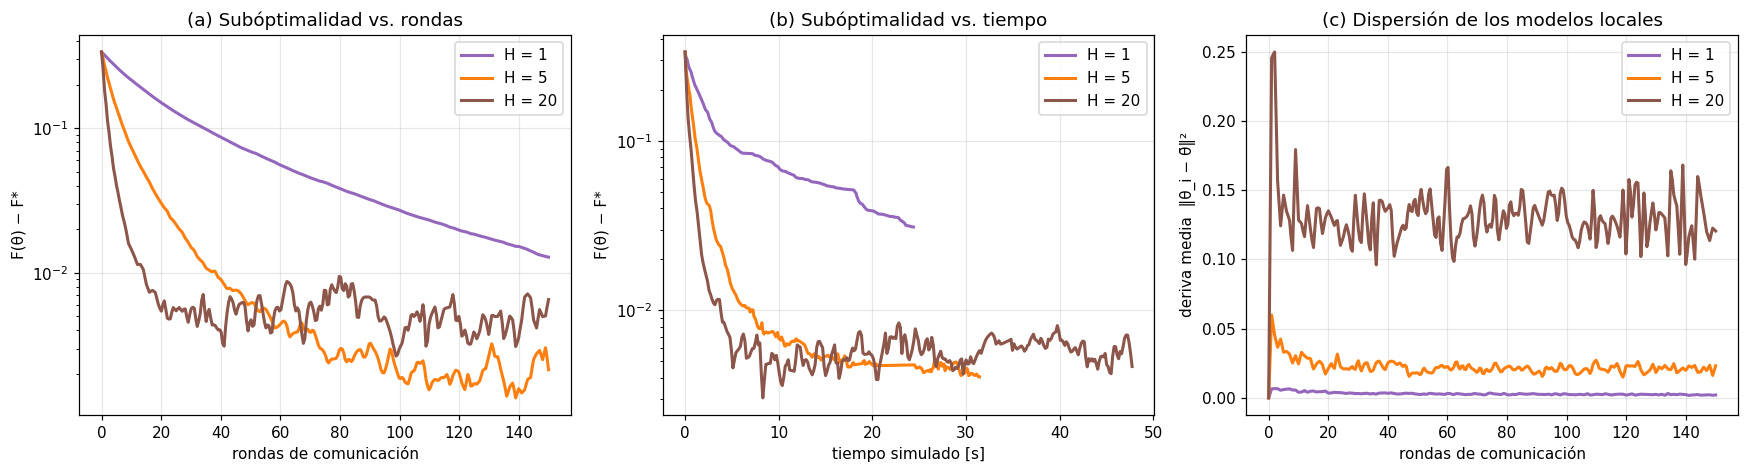

Subóptimalidad final (promedio de semillas) y deriva media:
  H= 1 | F−F* = 1.28e-02 | deriva = 0.003
  H= 5 | F−F* = 2.14e-03 | deriva = 0.023
  H=20 | F−F* = 6.55e-03 | deriva = 0.131


In [13]:
H_LISTA = [1, 5, 20]
R_DRIFT = 150
res_H = {H: [fedavg(eta=ETA_FED, H=H, seed=SEED + 100 * s, C=C_FED, t_max=1e12, r_max=R_DRIFT) for s in range(N_SEMILLAS)]
         for H in H_LISTA}
col_H = {1: "tab:purple", 5: "tab:orange", 20: "tab:brown"}

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for H, hs in res_H.items():
    g, m, s = curva_media(hs, "ronda", "perdida", transformar=subopt)
    ax[0].plot(g, m, color=col_H[H], lw=2, label=f"H = {H}")
    g, m, s = curva_media(hs, "tiempo", "perdida", transformar=subopt)
    ax[1].plot(g / 1e3, m, color=col_H[H], lw=2, label=f"H = {H}")
    g, m, s = curva_media(hs, "ronda", "deriva")
    ax[2].plot(g, m, color=col_H[H], lw=2, label=f"H = {H}")
ax[0].set(xlabel="rondas de comunicación", ylabel="F(θ) − F*", yscale="log", title="(a) Subóptimalidad vs. rondas")
ax[1].set(xlabel="tiempo simulado [s]", ylabel="F(θ) − F*", yscale="log", title="(b) Subóptimalidad vs. tiempo")
ax[2].set(xlabel="rondas de comunicación", ylabel="deriva media  ‖θ_i − θ̄‖²", title="(c) Dispersión de los modelos locales")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

print("Subóptimalidad final (promedio de semillas) y deriva media:")
for H, hs in res_H.items():
    print(f"  H={H:2d} | F−F* = {np.mean([subopt(h['perdida'])[-1] for h in hs]):.2e} | "
          f"deriva = {np.mean([h['deriva'][1:].mean() for h in hs]):.3f}")

### 4.3 (Opcional) Experimentos para explorar

Cambie el valor indicado, vuelva a ejecutar **desde la celda de configuración** y anote qué cambia:

1. `SKEW = 0` (datos IID): ¿desaparece la meseta de $H=20$? ¿Qué le dice eso sobre el origen de la deriva?
2. `REZAGADOS = {}` y `SNR_DB_REZAGADO = SNR_DB_MEDIO`: ¿qué le ocurre a la ventaja en *tiempo* de FedAvg/SlowMo sobre PSSGD?
3. `GRAFO = "anillo"` (y recalcule `A_D2D`): ¿cómo cambia D2D? Relaciónelo con $|\lambda_2(\mathbf{W})|$.
4. `BETA = 0.9` y `ALPHA = 1.0` en SlowMo; luego `BETA = 0` (¿qué algoritmo recupera?).
5. `BW_HZ = 500e3`: con 10 veces más ancho de banda, ¿sigue siendo la comunicación el cuello de botella? ¿Qué pasa con la ventaja de FedAvg?

## 5. Preguntas de análisis

Responda cada pregunta en 5–10 líneas, **citando evidencia de sus propias gráficas** (números o formas de curva) y las ecuaciones de la capa física.

**Pregunta 1 — Capacidad de canal y número de rondas.**
El tiempo de cada mensaje es $T=32p/(B\log_2(1+\mathrm{SNR}\,|h|^2))$. Con base en el panel (a) y el panel (b) de la sección 4.1, calcule aproximadamente cuántas rondas completó PSSGD frente a FedAvg dentro de `T_MAX_MS`. Si se duplicara $B$ (o la SNR en dB aumentara 6 dB), ¿qué esperaría que ocurra con la ventaja de FedAvg sobre PSSGD? ¿En qué régimen (limitado por comunicación vs. por cómputo) deja de valer la pena aumentar $H$?

**Pregunta 2 — Desvanecimiento Rayleigh y rezagados.**
Observe el histograma de la sección 2.3. (a) ¿Por qué el máximo de $N$ tiempos de ronda tiene una media y una cola mucho mayores que la de un nodo típico? (b) Explique por qué un *outage* profundo ($|h|^2\to0$) afecta más a un esquema síncrono que espera a todos que a uno que muestrea solo una fracción $C$ de los clientes. (c) ¿Qué mecanismo a nivel de capa física o de protocolo (por ejemplo, *timeouts*, selección de clientes por calidad de canal, o repetición) podría mitigar el problema, y qué sesgo estadístico introduciría al ignorar a los nodos con peor canal si estos poseen datos únicos (recuerde que los nodos 3 y 7 tienen una fracción de etiquetas particular)?

**Pregunta 3 — Interferencia, acceso múltiple y consenso D2D.**
En D2D los nodos transmiten simultáneamente a sus vecinos, pero en un sistema real comparten el espectro. (a) Si la SINR de un enlace es $P|h|^2/(N_0B+I)$, ¿cómo cambia el tiempo de ronda cuando aumenta el grado del grafo $d_{\max}$ y con él la interferencia (o el número de intervalos de tiempo/frecuencia necesarios para agendar a los vecinos)? (b) Compare los resultados del anillo y del grafo aleatorio (`|λ2(W)|`, error de consenso). Argumente por qué existe un compromiso entre *velocidad de consenso* (más aristas) y *costo por ronda* (más interferencia / más tiempo de aire).

**Pregunta 4 — Deriva del cliente, potencia en subida y SlowMo.**
(a) Con la sección 4.2, explique por qué $H=20$ reduce el número de transmisiones de subida y, por tanto, la energía de comunicación $E_{\text{sub}}\approx P_{\text{tx}}\,T_{\text{subida}}$ por unidad de progreso, pero puede dejar una meseta de subóptimalidad. (b) SlowMo no transmite ningún bit extra frente a FedAvg: ¿en qué sentido "compra" convergencia gratis desde el punto de vista del enlace? ¿Qué le ocurre cuando $\beta\to1$ con $\eta$ fijo? (c) Proponga una política que ajuste $H$ según el estado del canal (por ejemplo, más pasos locales cuando el enlace está en desvanecimiento profundo) y discuta qué riesgo introduce sobre la deriva.

---

### Referencias sugeridas

* McMahan, Moore, Ramage, Hampson, Agüera y Arcas. *Communication-Efficient Learning of Deep Networks from Decentralized Data* (FedAvg). AISTATS, 2017.
* Wang, Tantia, Ballas, Rabbat. *SlowMo: Improving Communication-Efficient Distributed SGD with Slow Momentum*. ICLR, 2020.
* Xiao, Boyd. *Fast linear iterations for distributed averaging*. Systems & Control Letters, 2004 (matrices de pesos y consenso).
* Karimireddy et al. *SCAFFOLD: Stochastic Controlled Averaging for Federated Learning*. ICML, 2020 (deriva del cliente).